In [97]:
import sys
import os
import math
from typing import NamedTuple

from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold

import jax
import jax.numpy as jnp
import optax


sys.path.append(os.path.join(os.getcwd(), 'import'))

from utils import read_utils
from utils import plot_utils
from utils import train_utils
from utils import artificializer

from models import clm_sep as clm
from models import hgm_sep as hgm

In [98]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(artificializer)
importlib.reload(clm)
importlib.reload(hgm)

<module 'models.hgm_sep' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/Work/Workspaces/UNIVIE/JetBrains/DataSpell/MSc_Thesis/worm-2025-fieseler/import/models/hgm_sep.py'>

# Functions

In [99]:
def fit_analytical_model(splits, B_ll, N_res):
	p = 2

	model_per_split = list()
	neuron_score_per_split = list()
	mpe_loss_per_split = list()
	mpe_loss_tr_per_split = list()
	for train, eval in splits:
		B_ll_train, B_ll_eval = B_ll[train], B_ll[eval]
		N_res_train, N_res_eval = N_res[train], N_res[eval]

		model = LinearRegression(fit_intercept=False)
		model.fit(B_ll_train, N_res_train)

		N_res_pred = model.predict(B_ll_eval)

		loss = jnp.mean(jnp.mean(jnp.abs(N_res_pred - N_res_eval) ** p, axis=0))
		loss_tr = jnp.mean(jnp.mean(jnp.abs(model.predict(B_ll_train) - N_res_train) ** p, axis=0))

		score_per_neuron = [(r2_score(trace, trace_pred) if trace.var() > 0 else 0) for trace, trace_pred in zip(N_res_eval.T, N_res_pred.T)]

		model_per_split.append(model)
		neuron_score_per_split.append(np.array(score_per_neuron))
		mpe_loss_per_split.append(loss)
		mpe_loss_tr_per_split.append(loss_tr)

	return model_per_split, np.array(neuron_score_per_split), np.array(mpe_loss_per_split), np.array(mpe_loss_tr_per_split)

In [100]:
def fit_analytical_models(filenames, discrete_states, eigenworms, traces_residual):
	models_models_art = list()
	models_scores_art = list()
	models_mpe_losses_art = list()
	models_mpe_losses_tr_art = list()

	for i in range(len(filenames)):
		print(f'{i+1}/{len(filenames)}: {filenames[i]} ', end='')

		splits = list(StratifiedKFold(n_splits=5).split(np.zeros(eigenworms[i].values.shape[0]), discrete_states[i]['REV'].values))

		(model_per_split,
		 neuron_score_per_split,
		 mpe_loss_per_split, mpe_loss_tr_per_split) = fit_analytical_model(splits,
												   eigenworms[i].values,
												   traces_residual[i].values)

		models_models_art.append(model_per_split)
		models_scores_art.append(neuron_score_per_split)
		models_mpe_losses_art.append(mpe_loss_per_split)
		models_mpe_losses_tr_art.append(mpe_loss_tr_per_split)

	return models_models_art, models_scores_art, models_mpe_losses_art, models_mpe_losses_tr_art

In [101]:
def train_numerical_model(model, splits, B_ll, N_res, N_man=None, hyperparameters=None):
	is_hgm = model.get_type()

	#region hyperparamters ===============================================================
	seeds = jax.random.PRNGKey(0), jax.random.PRNGKey(1), jax.random.PRNGKey(2), jax.random.PRNGKey(3)

	if hyperparameters is None:
		hyperparameters = {
			'max_epochs': 2000,
			'max_patience': 2000 / 4,
			'learning_rate': 1E-2,
			'w1_reg_lambda': 0.0,
			'w2_reg_lambda': 0.0,
		}

	max_epochs = hyperparameters['max_epochs']
	max_patience = hyperparameters['max_patience']

	learning_rate = hyperparameters['learning_rate']

	reg_lambdas = hyperparameters['w1_reg_lambda'], hyperparameters['w2_reg_lambda']
	#endregion ===========================================================================

	n_neurons = N_res.shape[1]
	if is_hgm: n_dimensions = N_man.shape[1]
	n_behaviors_ll = B_ll.shape[1]

	# training loop =============================
	params_per_split = list()
	neuron_scores_per_split = list()
	losses_per_split = list()
	losses_tr_per_split = list()
	mpe_losses_per_split = list()
	mpe_losses_tr_per_split = list()
	__grads_per_split = list()
	for s_id, (train, eval) in enumerate(splits):
		#region splitting and initializing (this also moves the data to the GPU) ==========================
		B_ll_train, B_ll_eval = jnp.array(B_ll[train]), jnp.array(B_ll[eval])
		if is_hgm: N_man_train, N_man_eval = jnp.array(N_man[train]), jnp.array(N_man[eval])
		N_res_train, N_res_eval = jnp.array(N_res[train]), jnp.array(N_res[eval])

		if is_hgm:
			params = model.init_params(seeds, (n_behaviors_ll, n_neurons), (n_dimensions, n_neurons))
		else:
			params = model.init_params(seeds, (n_behaviors_ll, n_neurons))

		# optimizer = optax.adam(learning_rate=optax.cosine_decay_schedule(
		# 	init_value=learning_rate,
		# 	decay_steps=max_epochs,
		# 	alpha=1E-2
		# ))
		optimizer = optax.adam(learning_rate)
		opt_state = optimizer.init(params)
		#endregion ========================================================================================

		if is_hgm:
			losses = [model.loss_fn(params, B_ll_eval, N_man_eval, N_res_eval, reg_lambdas).item()]
			losses_tr = [model.loss_fn(params, B_ll_train, N_man_train, N_res_train, reg_lambdas).item()]
			mpe_losses = [model.mpe_loss_fn(params, B_ll_eval, N_man_eval, N_res_eval).item()]
			mpe_losses_tr = [model.mpe_loss_fn(params, B_ll_train, N_man_train, N_res_train).item()]
		else:
			losses = [model.loss_fn(params, B_ll_eval, N_res_eval, reg_lambdas).item()]
			losses_tr = [model.loss_fn(params, B_ll_train, N_res_train, reg_lambdas).item()]
			mpe_losses = [model.mpe_loss_fn(params, B_ll_eval, N_res_eval).item()]
			mpe_losses_tr = [model.mpe_loss_fn(params, B_ll_train, N_res_train).item()]
		__grads = list()

		best_params = params
		best_loss = sys.float_info.max
		best_loss_tr = sys.float_info.max
		best_mpe_loss = sys.float_info.max
		best_mpe_loss_tr = sys.float_info.max

		# lr_step = 0
		patience = 0
		for epoch in range(max_epochs):
			if is_hgm:
				params, opt_state, __grad = model.update(optimizer.update, opt_state, params, B_ll_train, N_man_train, N_res_train, reg_lambdas)
				loss = model.loss_fn(params, B_ll_eval, N_man_eval, N_res_eval, reg_lambdas).item()
				loss_tr = model.loss_fn(params, B_ll_train, N_man_train, N_res_train, reg_lambdas).item()
				mpe_loss = model.mpe_loss_fn(params, B_ll_eval, N_man_eval, N_res_eval).item()
				mpe_loss_tr = model.mpe_loss_fn(params, B_ll_train, N_man_train, N_res_train).item()
			else:
				params, opt_state, __grad = model.update(optimizer.update, opt_state, params, B_ll_train, N_res_train, reg_lambdas)
				loss = model.loss_fn(params, B_ll_eval, N_res_eval, reg_lambdas).item()
				loss_tr = model.loss_fn(params, B_ll_train, N_res_train, reg_lambdas).item()
				mpe_loss = model.mpe_loss_fn(params, B_ll_eval, N_res_eval).item()
				mpe_loss_tr = model.mpe_loss_fn(params, B_ll_train, N_res_train).item()
			__grads.append(__grad)

			#region early stopping ===========================================================================
			if epoch >= max_patience:  # give it an initial time
				if loss < best_loss:
					patience = 0

					best_params = params
					best_loss = loss
					best_loss_tr = loss_tr
					best_mpe_loss = mpe_loss
					best_mpe_loss_tr = mpe_loss_tr
				else:
					patience += 1
					if patience > max_patience:
						params = best_params
						losses = losses + [best_loss for _ in range(max_epochs - epoch)]
						losses_tr = losses_tr + [best_loss_tr for _ in range(max_epochs - epoch)]
						mpe_losses = mpe_losses + [best_mpe_loss for _ in range(max_epochs - epoch)]
						mpe_losses_tr = mpe_losses_tr + [best_mpe_loss_tr for _ in range(max_epochs - epoch)]

						print(f'Stopped after {epoch} epochs: ', end='')
						break

						# lr_step += 1
						# optimizer = optax.adam(learning_rate / (10 ** lr_step))
						# patience = 0
						# print(f'\nReduced learning rate from {learning_rate / (10 ** (lr_step - 1))} to {learning_rate / (10 ** lr_step)} after epoch {epoch} in split {s_id}', end='')
			#endregion =======================================================================================

			losses.append(loss)
			losses_tr.append(loss_tr)
			mpe_losses.append(mpe_loss)
			mpe_losses_tr.append(mpe_loss_tr)

		params_per_split.append(params)
		losses_per_split.append(losses)
		losses_tr_per_split.append(losses_tr)
		mpe_losses_per_split.append(mpe_losses)
		mpe_losses_tr_per_split.append(mpe_losses_tr)

		__grads_per_split.append(__grads)

		print(f'Split {s_id} completed. ', end='')

		# predicting and scoring ========================================================================
		if is_hgm:
			score_per_neuron = model.score_fn(params, B_ll_eval, N_man_eval, N_res_eval)
		else:
			score_per_neuron = model.score_fn(params, B_ll_eval, N_res_eval)
		neuron_scores_per_split.append(score_per_neuron)
		# ===============================================================================================

	# ===========================================

	return params_per_split, np.array(neuron_scores_per_split), np.array(losses_per_split), np.array(losses_tr_per_split), np.array(mpe_losses_per_split), np.array(mpe_losses_tr_per_split), __grads_per_split

In [102]:
def train_numerical_models(model, filenames, discrete_states, eigenworms, traces_residual, neural_modes=None):
	models_params = list()
	models_scores = list()
	models_losses = list()
	models_losses_tr = list()
	models_mpe_losses = list()
	models_mpe_losses_tr = list()
	__models_grads = list()

	for i in range(len(filenames)):
		print(f'\n{i + 1}/{len(filenames)}: {filenames[i]} ', end='')

		splits = list(StratifiedKFold(n_splits=5).split(np.zeros(eigenworms[i].values.shape[0]), discrete_states[i]['REV'].values))

		(params_per_split,
		 neuron_scores_per_split,
		 losses_per_split, losses_tr_per_split,
		 mpe_losses_per_split, mpe_losses_tr_per_split,
		 __grads_per_split) = train_numerical_model(model, splits,
													eigenworms[i].values,
													traces_residual[i].values,
													neural_modes[i].values if neural_modes is not None else None)

		models_params.append(params_per_split)
		models_scores.append(neuron_scores_per_split)
		models_losses.append(losses_per_split)
		models_losses_tr.append(losses_tr_per_split)
		models_mpe_losses.append(mpe_losses_per_split)
		models_mpe_losses_tr.append(mpe_losses_tr_per_split)
		__models_grads.append(__grads_per_split)

	return models_params, models_scores, models_losses, models_losses_tr, models_mpe_losses, models_mpe_losses_tr, __models_grads

In [103]:
def assemble(filenames, traces, clm_models_scores, hgm_models_scores):
	neurons_labels = [traces[i].columns for i in range(len(filenames))]

	neuron_scores = dict()
	clm_models_avg_scores = [np.mean(scores, axis=0) for scores in clm_models_scores]
	hgm_models_avg_scores = [np.mean(scores, axis=0) for scores in hgm_models_scores]
	for label_list, score_clm_list, score_hgm_list in zip(neurons_labels, clm_models_avg_scores, hgm_models_avg_scores):
		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_clm_new, score_hgm_new = np.array(score_clm_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_clm_new = score_clm_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_clm_new, score_hgm_new)
				else:
					score_clm_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_clm_prev, score_clm_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

In [104]:
# read_ids = [0, 4, 5, 6, 27, 30, 31, 32, 33]
read_ids = [4]
plot_id = 4

# dims = 2
dims_generation = 2
weights = (0.5, 2.)

# selection_n = ['DB01', 'VB02', 'RMDDR', 'RMDDL', 'SMDDR', 'SMDVR']  # high c portion for worm 33
# selection_n = ['VB02', 'SMDDR', 'SMDDL', 'RMDDR', 'RMDDL', 'SMDVR']  # high c portion for worm 24
# selection_n = ['DD01', 'VB02', 'SMDDR', 'DB01', 'RMDDR', 'AVAR', 'AVAL']
selection_n = ['VB02', 'RMDDR', 'AVAR', 'AVAL']
selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']


regression = False
artificial = False
gfp = False

# read & preprocess (GCamp & GFP)

In [105]:
path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gcamp')
file_ids_gcamp, filenames_gcamp, continuous_behaviors_gcamp, discrete_states_gcamp, eigenworms_gcamp, kymographs_gcamp, traces_gcamp = read_utils.get_data(path, read_ids)

for i in range(len(filenames_gcamp)):
	mask = eigenworms_gcamp[i].notna().all(axis=1)
	#continuous_behaviors_gcamp[i] = continuous_behaviors_gcamp[i][mask]
	discrete_states_gcamp[i] = discrete_states_gcamp[i][mask]
	eigenworms_gcamp[i] = eigenworms_gcamp[i][mask]
	traces_gcamp[i] = traces_gcamp[i][mask]

	#kymographs_gcamp[i] = kymographs_gcamp[i][mask]
	#filenames_gcamp[i] = filenames_gcamp[i][mask]

discrete_states_gcamp = [ds[selection_bhl] for ds in discrete_states_gcamp]


path_gfp = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gfp')
file_ids_gfp, filenames_gfp, continuous_behaviors_gfp, discrete_states_gfp, eigenworms_gfp, kymographs_gfp, traces_gfp = read_utils.get_data(path_gfp)

for i in range(len(filenames_gfp)):
	mask = eigenworms_gfp[i].notna().all(axis=1)
	#continuous_behaviors_gfp[i] = continuous_behaviors_gfp[i][mask]
	discrete_states_gfp[i] = discrete_states_gfp[i][mask]
	eigenworms_gfp[i] = eigenworms_gfp[i][mask]
	traces_gfp[i] = traces_gfp[i][mask]

	#kymographs_gfp[i] = kymographs_gfp[i][mask]
	#filenames_gfp[i] = filenames_gfp[i][mask]

discrete_states_gfp = [ds[selection_bhl] for ds in discrete_states_gfp]

# ARTIFICIAL DATA

In [106]:
if artificial:
	file_ids_art = file_ids_gcamp.copy()
	filenames_art = list()
	discrete_states_art = discrete_states_gcamp.copy()
	eigenworms_art = eigenworms_gcamp.copy()
	neural_modes_art = list()
	traces_reconstructed_art = list()
	traces_residual_art = list()
	traces_art = list()
	for i in range(len(filenames_gcamp)):
		(filename_art,
		 neural_modes_art_,
		 traces_reconstructed_art_,
		 traces_residual_art_,
		 traces_art_,
		 params_art_,
		 params_cca_art_) = artificializer.artificialize(weights, hgm,
														 filenames_gcamp[i],
														 traces_gcamp[i].columns,
														 eigenworms_art[i],
														 discrete_states_art[i],
														 n_dimensions=dims_generation)
		filenames_art.append(filename_art)
		neural_modes_art.append(neural_modes_art_)
		traces_reconstructed_art.append(traces_reconstructed_art_)
		traces_residual_art.append(traces_residual_art_)
		traces_art.append(traces_art_)

In [107]:
if artificial:
	plot_utils.plot_traces(f'[{filenames_art[file_ids_art.index(plot_id)]}] artificial neural traces residual',
						   discrete_states_art[file_ids_art.index(plot_id)]['REV'],
						   traces_residual_art[file_ids_art.index(plot_id)][selection_n],
						   plots_per_row=1, ylimits=None)

In [108]:
if artificial and regression:
	# train alr art

	(alr_models_models_art,
	 alr_models_scores_art,
	 alr_models_losses_art, alr_models_losses_tr_art) = fit_analytical_models(filenames_art,
																			  discrete_states_art,
																			  eigenworms_art,
																			  traces_residual_art)

In [109]:
if artificial:
	# train clm art

	(clm_models_params_art,
	 clm_models_scores_art,
	 clm_models_losses_art, clm_models_losses_tr_art,
	 clm_models_mpe_losses_art, clm_models_mpe_losses_tr_art,
	 __clm_models_grads_art) = train_numerical_models(clm,
													  filenames_art,
													  discrete_states_art,
													  eigenworms_art,
													  traces_residual_art)

In [110]:
if artificial and regression:
	plot_utils.plot_losses_splits('artificial clm vs alr: mpe train',
								  filenames_art,
								  clm_models_mpe_losses_tr_art, [loss[:, None] * np.ones((1, clm_models_mpe_losses_tr_art[0].shape[1])) for loss in alr_models_losses_tr_art],
								  plots_per_row=4, ylimits=None)

In [111]:
if artificial and regression:
	plot_utils.plot_losses_splits('artificial clm vs alr: eval',
								  filenames_art,
								  clm_models_mpe_losses_art, [loss[:, None] * np.ones((1, clm_models_mpe_losses_art[0].shape[1])) for loss in alr_models_losses_art],
								  plots_per_row=4, ylimits=None)

In [112]:
if artificial:
	# train hgm art

	(hgm_models_params_art,
	 hgm_models_scores_art,
	 hgm_models_losses_art, hgm_models_losses_tr_art,
	 hgm_models_mpe_losses_art, hgm_models_mpe_losses_tr_art,
	 __hgm_models_grads_art) = train_numerical_models(hgm,
													  filenames_art,
													  discrete_states_art,
													  eigenworms_art,
													  traces_residual_art,
													  neural_modes_art)

In [113]:
if artificial:
	plot_utils.plot_losses_splits('artificial hgm vs clm: train',
								  filenames_art,
								  hgm_models_mpe_losses_tr_art, clm_models_mpe_losses_tr_art,
								  plots_per_row=4, ylimits=None)

In [114]:
if artificial:
	plot_utils.plot_losses_splits('artificial hgm vs clm: eval',
								  filenames_art,
								  hgm_models_mpe_losses_art, clm_models_mpe_losses_art,
								  plots_per_row=4, ylimits=None)

### performance

In [115]:
if artificial:
	# assemble_art

	neuron_scores_art = assemble(filenames_art, traces_art, clm_models_scores_art, hgm_models_scores_art)

In [116]:
if artificial:
	plot_utils.plot_performance_plot({key: neuron_scores_art[key] for key in selection_n}, None,
									 limits=None, content_size=20)

In [117]:
if artificial:
	plot_utils.plot_improvement_plot({key: neuron_scores_art[key] for key in selection_n}, None,
									 limits=None, content_size=20)

### traces check

In [118]:
if artificial:
	alr_predicted_traces_art = [[
		pd.DataFrame(data=model.predict(eigenworms_art[i].values),
					 columns=traces_art[i].columns) for model in alr_models_models_art[i]
	] for i in range(len(traces_art))]

	clm_predicted_traces_art = [[
		pd.DataFrame(data=clm.predict(eigenworms_art[i].values, params['W']),
					 columns=traces_art[i].columns) for params in clm_models_params_art[i]
	] for i in range(len(traces_art))]

	hgm_predicted_traces_art = [[
		pd.DataFrame(data=hgm.predict(eigenworms_art[i].values, neural_modes_art[i].values, params['W1'], params['W2']),
					 columns=traces_art[i].columns) for params in hgm_models_params_art[i]
	] for i in range(len(traces_art))]

In [119]:
# if artificial:
# 	# best improvements
# 	neuron_diffs = {key: np.mean(neuron_scores_art[key][1] - neuron_scores_art[key][0]) for key in neuron_scores_art.keys()}
# 	selection_n = [label for label in list(reversed(list(np.array(list(neuron_diffs.keys()))[np.argsort(np.array(list(neuron_diffs.values())))]))) if label in traces_art[plot_id].columns][:4]
#
# 	# best hgm scores
# 	neuron_hgmss = {key: np.mean(neuron_scores_art[key][1]) for key in neuron_scores_art.keys()}
# 	selection_n = [label for label in list(reversed(list(np.array(list(neuron_hgmss.keys()))[np.argsort(np.array(list(neuron_hgmss.values())))]))) if label in traces_art[plot_id].columns][:4]

In [120]:
if artificial:
	splits = 1
	plot_utils.plot_traces_x_splits(
		f'{filenames_art[file_ids_art.index(plot_id)]} splits {1}-{splits} artificial hgm & clm predictions residuals',
		discrete_states_art[file_ids_art.index(plot_id)]['REV'],
		traces_residual_art[file_ids_art.index(plot_id)][selection_n],
		[hgm_predicted_traces_art[file_ids_art.index(plot_id)][i][selection_n] for i in range(splits)],
		[clm_predicted_traces_art[file_ids_art.index(plot_id)][i][selection_n] for i in range(splits)],
		n_plots=len(selection_n), plots_per_row=1, ylimits=(-0.8, 0.8))

In [121]:
if artificial:
	splits = 1
	plot_utils.plot_traces_x_splits(
		f'{filenames_art[file_ids_art.index(plot_id)]} splits {1}-{splits} artificial hgm & clm predictions residuals',
		discrete_states_art[file_ids_art.index(plot_id)]['REV'],
		traces_residual_art[file_ids_art.index(plot_id)][selection_n],
		[hgm_predicted_traces_art[file_ids_art.index(plot_id)][i][selection_n] for i in range(splits)],
		[clm_predicted_traces_art[file_ids_art.index(plot_id)][i][selection_n] for i in range(splits)],
		n_plots=len(selection_n), plots_per_row=1, ylimits=(-0.8, 0.8), plot_first=True)

# GCAMP

### manifold

In [122]:
(neural_modes_gcamp, _,
 traces_manifold_gcamp, _,
 cca_loadings_man_gcamp,
 vars_expl_man_gcamp, vars_expl_man_rs_gcamp) = train_utils.get_manifolds(traces_gcamp,
																		  discrete_states_gcamp,
																		  n_cc=2, n_pc=5)

traces_residual_gcamp = [pd.DataFrame(data=trace.values - trace_manifold.values, columns=trace.columns) for trace, trace_manifold in zip(traces_gcamp, traces_manifold_gcamp)]

0.4746061701457467 0.7491699410776036


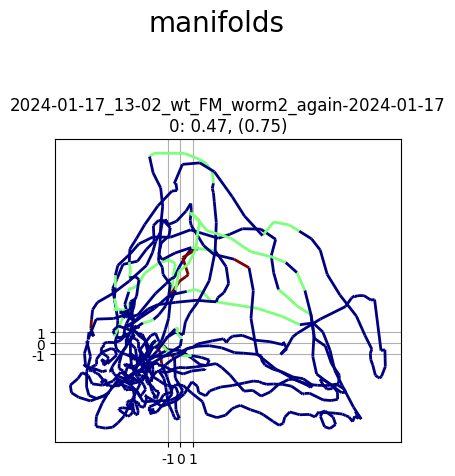

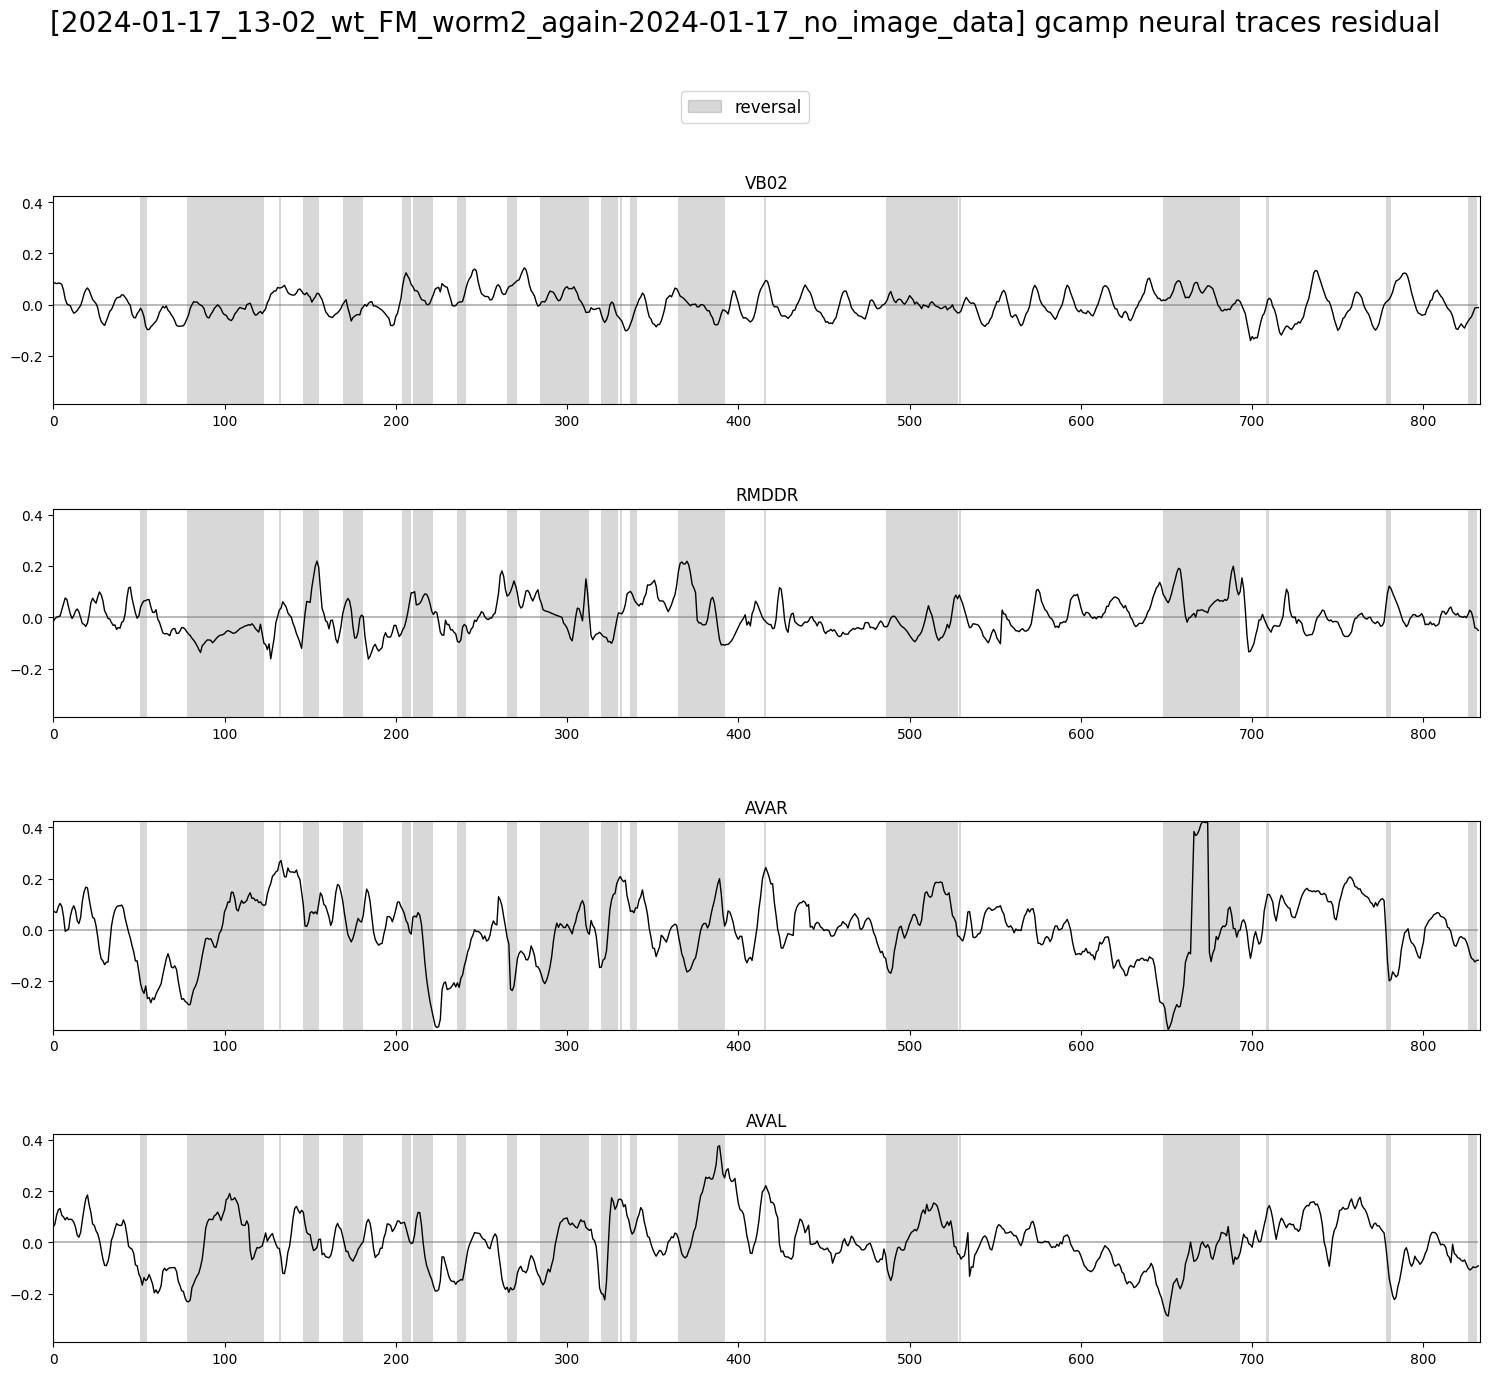

In [123]:
plot_utils.plot_manifolds(filenames_gcamp,
						  neural_modes_gcamp,
						  discrete_states_gcamp,
						  vars_expl_man_gcamp, vars_expl_man_rs_gcamp,
						  plots_per_row=4)

plot_utils.plot_traces(f'[{filenames_gcamp[file_ids_gcamp.index(plot_id)]}] gcamp neural traces residual',
					   discrete_states_gcamp[file_ids_gcamp.index(plot_id)]['REV'],
					   traces_residual_gcamp[file_ids_gcamp.index(plot_id)][selection_n],
					   plots_per_row=1, ylimits=None)

### ALR

In [124]:
if regression:
	(alr_models_models_gcamp,
	 alr_models_scores_gcamp,
	 alr_models_losses_gcamp, alr_models_losses_tr_gcamp) = fit_analytical_models(filenames_gcamp,
																				  discrete_states_gcamp,
																				  eigenworms_gcamp,
																				  traces_residual_gcamp)

### CLM

In [125]:
(clm_models_params_gcamp,
 clm_models_scores_gcamp,
 clm_models_losses_gcamp, clm_models_losses_tr_gcamp,
 clm_models_mpe_losses_gcamp, clm_models_mpe_losses_tr_gcamp,
 __clm_models_grads_gcamp) = train_numerical_models(clm,
													filenames_gcamp,
													discrete_states_gcamp,
													eigenworms_gcamp,
													traces_residual_gcamp)


1/1: 2024-01-17_13-02_wt_FM_worm2_again-2024-01-17_no_image_data Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 

In [126]:
if regression:
	plot_utils.plot_losses_splits('gcamp clm vs alr: train',
								  filenames_gcamp,
								  clm_models_losses_tr_gcamp, [loss[:, None] * np.ones((1, clm_models_losses_tr_gcamp[0].shape[1])) for loss in alr_models_losses_tr_gcamp],
								  plots_per_row=4, ylimits=None)

In [127]:
if regression:
	plot_utils.plot_losses_splits('gcamp clm vs alr: eval',
								  filenames_gcamp,
								  clm_models_losses_gcamp,  [loss[:, None] * np.ones((1, clm_models_losses_gcamp[0].shape[1])) for loss in alr_models_losses_gcamp],
								  plots_per_row=4, ylimits=None)

### HGM

In [128]:
(hgm_models_params_gcamp,
 hgm_models_scores_gcamp,
 hgm_models_losses_gcamp, hgm_models_losses_tr_gcamp,
 hgm_models_mpe_losses_gcamp, hgm_models_mpe_losses_tr_gcamp,
 __hgm_models_grads_gcamp) = train_numerical_models(hgm,
													filenames_gcamp,
													discrete_states_gcamp,
													eigenworms_gcamp,
													traces_residual_gcamp,
													neural_modes_gcamp)


1/1: 2024-01-17_13-02_wt_FM_worm2_again-2024-01-17_no_image_data Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 

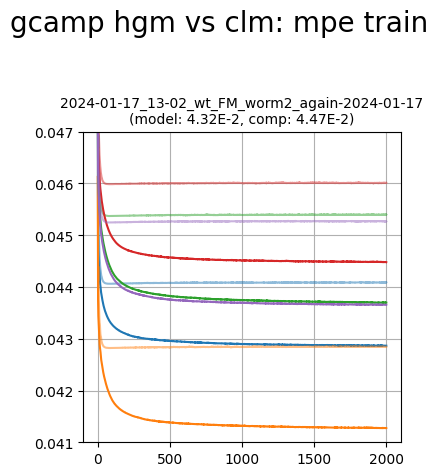

In [129]:
plot_utils.plot_losses_splits('gcamp hgm vs clm: mpe train',
							  filenames_gcamp,
							  hgm_models_mpe_losses_tr_gcamp, clm_models_mpe_losses_tr_gcamp,
							  plots_per_row=4, ylimits=(0.041, 0.047))

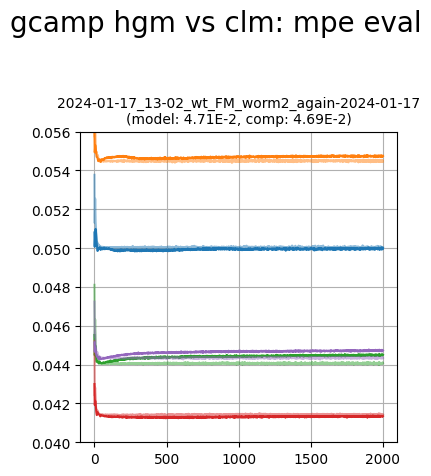

In [130]:
plot_utils.plot_losses_splits('gcamp hgm vs clm: mpe eval',
							  filenames_gcamp,
							  hgm_models_mpe_losses_gcamp, clm_models_mpe_losses_gcamp,
							  plots_per_row=4, ylimits=(0.04, 0.055))

### performance

In [131]:
neuron_scores_gcamp = assemble(filenames_gcamp, traces_gcamp, clm_models_scores_gcamp, hgm_models_scores_gcamp)

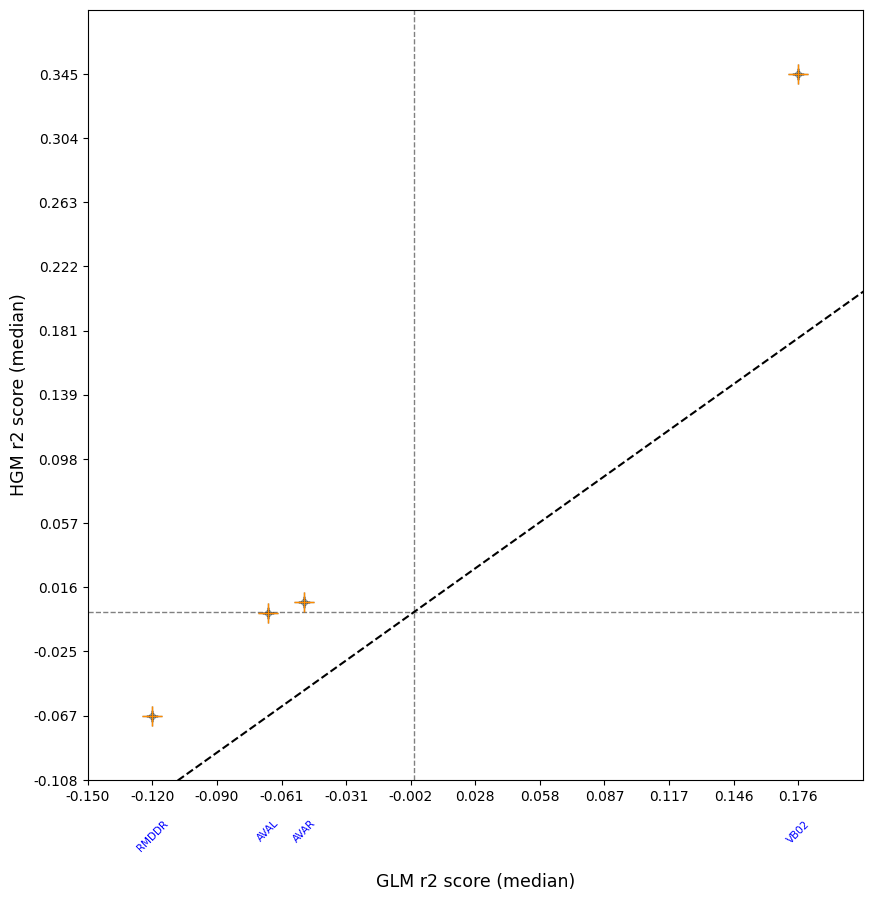

In [132]:
plot_utils.plot_performance_plot({key: neuron_scores_gcamp[key] for key in selection_n}, None,
								 limits=None, content_size=20)

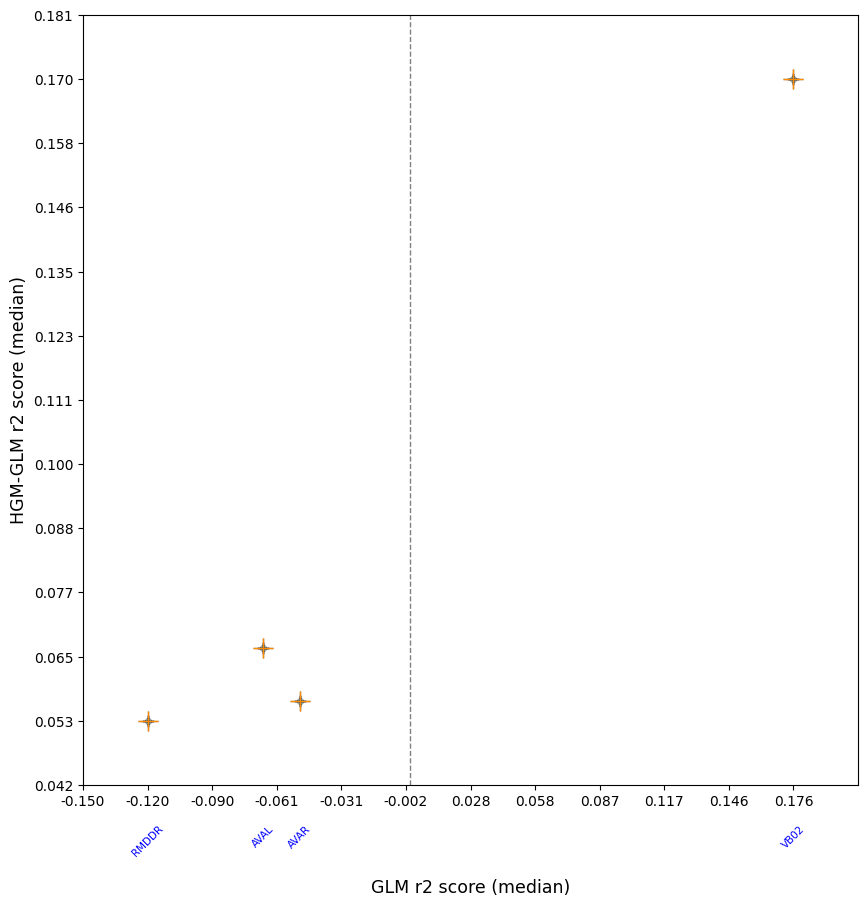

In [133]:
plot_utils.plot_improvement_plot({key: neuron_scores_gcamp[key] for key in selection_n}, None,
								 limits=None, content_size=20)

### traces check

In [134]:
# alr_predicted_traces_gcamp = [[
# 	pd.DataFrame(data=model.predict(eigenworms_gcamp[i].values),
# 				 columns=traces_gcamp[i].columns) for model in alr_models_models_gcamp[i]
# ] for i in range(len(traces_art))]

clm_predicted_traces_gcamp = [[
	pd.DataFrame(data=clm.predict(eigenworms_gcamp[i].values, params['W']),
				 columns=traces_gcamp[i].columns) for params in clm_models_params_gcamp[i]
] for i in range(len(traces_gcamp))]

hgm_predicted_traces_gcamp = [[
	pd.DataFrame(data=hgm.predict(eigenworms_gcamp[i].values, neural_modes_gcamp[i].values, params['W1'], params['W2']),
				 columns=traces_gcamp[i].columns) for params in hgm_models_params_gcamp[i]
] for i in range(len(traces_gcamp))]

In [135]:
# # best improvements
# neuron_diffs = {key: np.mean(neuron_scores_gcamp[key][1] - neuron_scores_gcamp[key][0]) for key in neuron_scores_gcamp.keys()}
# selection_n = [label for label in list(reversed(list(np.array(list(neuron_diffs.keys()))[np.argsort(np.array(list(neuron_diffs.values())))]))) if label in traces_gcamp[file_ids_gcamp.index(plot_id)].columns][:10]
#
# # best hgm scores
# neuron_hgmss = {key: np.mean(neuron_scores_gcamp[key][1]) for key in neuron_scores_gcamp.keys()}
# selection_n = [label for label in list(reversed(list(np.array(list(neuron_hgmss.keys()))[np.argsort(np.array(list(neuron_hgmss.values())))]))) if label in traces_gcamp[file_ids_gcamp.index(plot_id)].columns][:10]

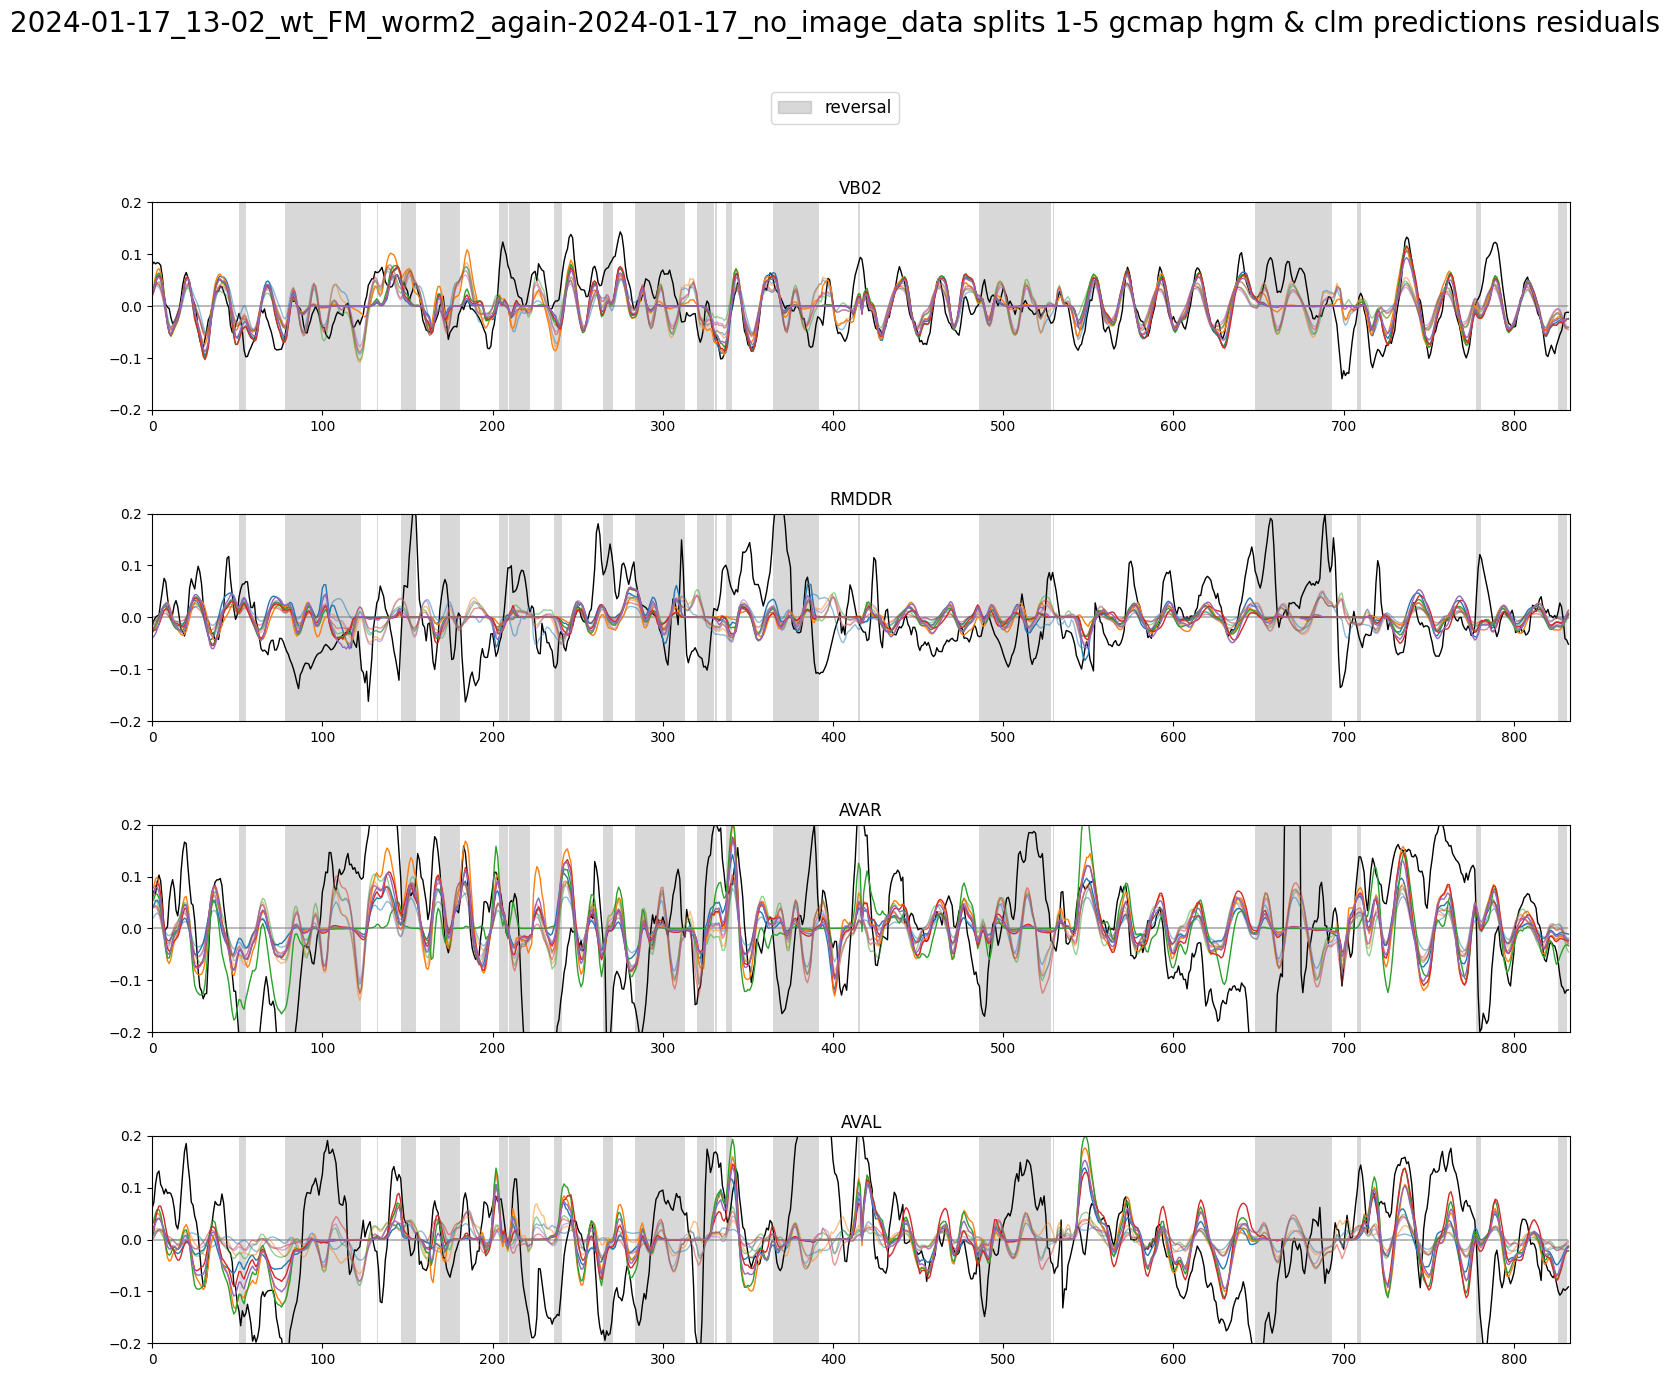

In [136]:
splits = 5
plot_utils.plot_traces_x_splits(
	f'{filenames_gcamp[file_ids_gcamp.index(plot_id)]} splits {1}-{splits} gcmap hgm & clm predictions residuals',
	discrete_states_gcamp[file_ids_gcamp.index(plot_id)]['REV'],
	traces_residual_gcamp[file_ids_gcamp.index(plot_id)][selection_n],
	[hgm_predicted_traces_gcamp[file_ids_gcamp.index(plot_id)][i][selection_n] for i in range(splits)],
	[clm_predicted_traces_gcamp[file_ids_gcamp.index(plot_id)][i][selection_n] for i in range(splits)],
	n_plots=len(selection_n), plots_per_row=1, ylimits=(-0.2, 0.2))

### __loss gradient per weights over time

In [137]:
# fig, axes = plt.subplots(1, 2, figsize=(12, 3))
# for ax in axes:
#     ax.set_ylim(-0.005, 0.004)
#
# for i in range(1):
# 	gradsW = np.array([val['W'] for val in __clm_models_grads_gcamp[-1][i]])
#
# 	gradsW1 = np.array([val['W1'] for val in __hgm_models_grads_gcamp[-1][i]])
# 	gradsW2 = np.array([val['W2'] for val in __hgm_models_grads_gcamp[-1][i]])
#
#
# 	axes[0].plot(np.mean(gradsW[:, :], axis=1))
#
# 	# axes[1].plot(np.mean(gradsW1[:, :, 10], axis=1))
# 	axes[1].plot(np.mean(gradsW2[:, :], axis=1))

# GFP

### manifold

In [139]:
if gfp:
	(neural_modes_gfp, _,
	 traces_manifold_gfp, _,
	 cca_loadings_man_gfp,
	 vars_expl_man_gfp, vars_expl_man_rs_gfp) = train_utils.get_manifolds(traces_gfp,
													   discrete_states_gfp,
													   n_cc=2, n_pc=5)

	traces_residual_gfp = [pd.DataFrame(data=trace.values - trace_manifold.values, columns=trace.columns) for trace, trace_manifold in zip(traces_gfp, traces_manifold_gfp)]

In [140]:
if gfp:
	plot_utils.plot_manifolds(filenames_gfp,
							  neural_modes_gfp,
							  discrete_states_gfp,
							  vars_expl_man_gfp, vars_expl_man_rs_gfp,
							  plots_per_row=4)

	plot_utils.plot_traces(f'[{filenames_gfp[file_ids_gfp.index(plot_id)]}] gfp neural traces residual',
						   discrete_states_gfp[file_ids_gfp.index(plot_id)]['REV'],
						   traces_residual_gfp[file_ids_gfp.index(plot_id)][['VB02', 'AVAR']],
						   plots_per_row=1, ylimits=None)

### ALR

In [141]:
if gfp and regression:
	(alr_models_models_gfp,
	 alr_models_scores_gfp,
	 alr_models_losses_gfp, alr_models_losses_tr_gfp) = fit_analytical_models(filenames_gfp,
																			  discrete_states_gfp,
																			  eigenworms_gfp,
																			  traces_residual_gfp)

### CLM

In [142]:
if gfp:
	(clm_models_params_gfp,
	 clm_models_scores_gfp,
	 clm_models_losses_gfp, clm_models_losses_tr_gfp,
	 clm_models_mpe_losses_gfp, clm_models_mpe_losses_tr_gfp,
	 __clm_models_grads_gfp) = train_numerical_models(clm,
													  filenames_gfp,
													  discrete_states_gfp,
													  eigenworms_gfp,
													  traces_residual_gfp)

In [143]:
if gfp and regression:
	plot_utils.plot_losses_splits('gfp clm vs alr: train',
								  filenames_gfp,
								  clm_models_losses_tr_gfp, [loss[:, None] * np.ones((1, clm_models_losses_tr_gfp[0].shape[1])) for loss in alr_models_losses_tr_gfp],
								  plots_per_row=4, ylimits=None)

In [144]:
if gfp and regression:
	plot_utils.plot_losses_splits('gfp clm vs alr: eval',
								  filenames_gfp,
								  clm_models_losses_gfp, [loss[:, None] * np.ones((1, clm_models_losses_gfp[0].shape[1])) for loss in alr_models_losses_gfp],
								  plots_per_row=4, ylimits=None)

### HGM

In [145]:
if gfp:
	(hgm_models_params_gfp,
	 hgm_models_scores_gfp,
	 hgm_models_losses_gfp, hgm_models_losses_tr_gfp,
	 hgm_models_mpe_losses_gfp, hgm_models_mpe_losses_tr_gfp,
	 __hgm_models_grads_gfp) = train_numerical_models(hgm,
													  filenames_gfp,
													  discrete_states_gfp,
													  eigenworms_gfp,
													  traces_residual_gfp,
													  neural_modes_gfp)

In [146]:
if gfp:
	plot_utils.plot_losses_splits('gfp hgm vs clm: train',
								  filenames_gfp,
								  hgm_models_losses_tr_gfp, clm_models_losses_tr_gfp,
								  plots_per_row=4, ylimits=None)

In [147]:
if gfp:
	plot_utils.plot_losses_splits('gfp hgm vs clm: eval',
								  filenames_gfp,
								  hgm_models_losses_gfp, clm_models_losses_gfp,
								  plots_per_row=4, ylimits=None)

# assemble

In [148]:
if gfp:
	neuron_scores_gfp = assemble(filenames_gfp, traces_gfp, clm_models_scores_gfp, hgm_models_scores_gfp)

# Plot

In [149]:
if gfp:
	plot_utils.plot_performance_plot({key: neuron_scores_gcamp[key] for key in ['VB02', 'AVAR']}, neuron_scores_gfp,
									 limits=(-1, 0.5, -1, 0.6), content_size=20)

In [150]:
if gfp:
	plot_utils.plot_improvement_plot({key: neuron_scores_gcamp[key] for key in ['VB02', 'AVAR']}, neuron_scores_gfp,
									 limits=(-1, 0.5, -0.25, 0.5), content_size=20)